# Laboratory Assignment 8: High-Performance Big Data Analytics Using R

**Dataset:** NYC Taxi & Limousine Commission (TLC) Yellow Taxi Trip Records  
**Environment:** Google Colab with an R runtime  
**Main packages:** `data.table`, `arrow`, `ggplot2`, `foreach`, `doParallel`, `microbenchmark`, `purrr`, `lubridate`

## Problem statement
Build a high-performance and scalable R analytics workflow for NYC Yellow Taxi trip data. The notebook cleans and prepares the data, joins pickup/drop-off zone details, analyzes demand and revenue patterns, compares functional/vectorized/`data.table` approaches, benchmarks sequential and parallel processing, and visualizes results.

## How to run
1. Upload this notebook to Google Colab.
2. Choose an **R runtime** (Runtime → Change runtime type, if the R option is available).
3. Run cells from top to bottom.
4. The first run downloads the official TLC Parquet data and zone lookup. Internet access is required.

**Resource note:** The default is one month of data, which contains millions of trips and is a substantial dataset. To reduce memory use, change `MONTHS` or set `MAX_ROWS_FOR_ANALYSIS` in the configuration cell. `MAX_ROWS_FOR_ANALYSIS <- Inf` uses all rows from the selected month(s). Benchmark results are measured in your runtime; they are not pre-filled or fabricated.

## 1. Install and load packages

In [1]:
required_packages <- c(
  "data.table", "arrow", "ggplot2", "foreach", "doParallel",
  "microbenchmark", "purrr", "lubridate"
)
missing_packages <- required_packages[
  !vapply(required_packages, requireNamespace, logical(1), quietly = TRUE)
]
if (length(missing_packages) > 0) {
  install.packages(missing_packages, repos = "https://cloud.r-project.org")
}

suppressPackageStartupMessages({
  library(data.table)
  library(arrow)
  library(ggplot2)
  library(foreach)
  library(doParallel)
  library(microbenchmark)
  library(purrr)
  library(lubridate)
})

cat("R version:", R.version.string, "\n")
cat("data.table:", as.character(packageVersion("data.table")), "\n")

Installing packages into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

also installing the dependencies ‘assertthat’, ‘iterators’




R version: R version 4.6.1 (2026-06-24) 
data.table: 1.18.6.1 


## 2. Configure the dataset and download official TLC files

In [4]:
# Download January 2024 NYC Yellow Taxi data

filename <- "yellow_tripdata_2024-01.parquet"

url <- paste0(
  "https://d37ci6vzurychx.cloudfront.net/trip-data/",
  filename
)

if (!file.exists(filename) || file.info(filename)$size == 0) {
  download.file(
    url = url,
    destfile = filename,
    mode = "wb",
    method = "libcurl"
  )
}

stopifnot(file.exists(filename), file.info(filename)$size > 0)

cat("Download successful:", filename, "\n")

Download successful: yellow_tripdata_2024-01.parquet 


In [6]:
library(arrow)
library(data.table)

taxi_data <- as.data.table(
  read_parquet("yellow_tripdata_2024-01.parquet")
)

# Display dataset dimensions
dim(taxi_data)

# Preview the first six rows
head(taxi_data)

# Check column names
names(taxi_data)

[1] 2964624      19

VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,store_and_fwd_flag,PULocationID,DOLocationID,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,Airport_fee
<int>,<dttm>,<dttm>,<int>,<dbl>,<int>,<chr>,<int>,<int>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
2,2024-01-01 00:57:55,2024-01-01 01:17:43,1,1.72,1,N,186,79,2,17.7,1.0,0.5,0.00,0,1,22.70,2.5,0
1,2024-01-01 00:03:00,2024-01-01 00:09:36,1,1.80,1,N,140,236,1,10.0,3.5,0.5,3.75,0,1,18.75,2.5,0
1,2024-01-01 00:17:06,2024-01-01 00:35:01,1,4.70,1,N,236,79,1,23.3,3.5,0.5,3.00,0,1,31.30,2.5,0
1,2024-01-01 00:36:38,2024-01-01 00:44:56,1,1.40,1,N,79,211,1,10.0,3.5,0.5,2.00,0,1,17.00,2.5,0
1,2024-01-01 00:46:51,2024-01-01 00:52:57,1,0.80,1,N,211,148,1,7.9,3.5,0.5,3.20,0,1,16.10,2.5,0
1,2024-01-01 00:54:08,2024-01-01 01:26:31,1,4.70,1,N,148,141,1,29.6,3.5,0.5,6.90,0,1,41.50,2.5,0


[1] "VendorID"              "tpep_pickup_datetime"  "tpep_dropoff_datetime"
 [4] "passenger_count"       "trip_distance"         "RatecodeID"           
 [7] "store_and_fwd_flag"    "PULocationID"          "DOLocationID"         
[10] "payment_type"          "fare_amount"           "extra"                
[13] "mta_tax"               "tip_amount"            "tolls_amount"         
[16] "improvement_surcharge" "total_amount"          "congestion_surcharge" 
[19] "Airport_fee"

In [12]:
# --- Configurations and Zone Lookup Download ---
MONTHS <- "2024-01"
MAX_ROWS_FOR_ANALYSIS <- 1000000 # Cap to 1 million rows for Colab memory safety, use Inf for all

# Map our downloaded file as the active trip files
trip_files <- "yellow_tripdata_2024-01.parquet"

# Download the official TLC Taxi Zone Lookup CSV
zone_file <- "taxi_zone_lookup.csv"
if (!file.exists(zone_file)) {
  download.file(
    url = "https://d37ci6vzurychx.cloudfront.net/misc/taxi_zone_lookup.csv",
    destfile = zone_file,
    mode = "wb"
  )
}
cat("Configurations set and zones lookup downloaded successfully!\n")

Configurations set and zones lookup downloaded successfully!


## 3. Read the data, inspect structure, and prepare selected columns

In [13]:
# Read only columns needed for the required analyses to reduce memory consumption.
needed_columns <- c(
  "VendorID", "tpep_pickup_datetime", "tpep_dropoff_datetime",
  "passenger_count", "trip_distance", "PULocationID", "DOLocationID",
  "payment_type", "fare_amount", "tip_amount", "tolls_amount", "total_amount"
)

read_one_month <- function(path) {
  # Open dataset safely directly from the file path
  available_cols <- names(arrow::open_dataset(path, format = "parquet")$schema)
  cols <- intersect(needed_columns, available_cols)
  if (!all(c("tpep_pickup_datetime", "tpep_dropoff_datetime",
             "PULocationID", "DOLocationID", "fare_amount", "total_amount") %in% cols)) {
    stop("Required columns were not found in: ", path)
  }
  as.data.table(arrow::read_parquet(path, col_select = cols))
}

# Read the file(s) and combine them into a single data.table
trip_parts <- lapply(trip_files, read_one_month)
taxi <- rbindlist(trip_parts, use.names = TRUE, fill = TRUE)
rm(trip_parts)
gc()

cat("Dimensions before cleaning:", nrow(taxi), "rows x", ncol(taxi), "columns\n")

,used,(Mb),gc trigger,(Mb),max used,(Mb)
Ncells,1679253,89.7,2861265,152.9,2861265,152.9
Vcells,78626803,599.9,195350397,1490.5,194245985,1482.0


Dimensions before cleaning: 2964624 rows x 12 columns


In [11]:
# Read only columns needed for the required analyses to reduce memory consumption.
needed_columns <- c(
  "VendorID", "tpep_pickup_datetime", "tpep_dropoff_datetime",
  "passenger_count", "trip_distance", "PULocationID", "DOLocationID",
  "payment_type", "fare_amount", "tip_amount", "tolls_amount", "total_amount"
)

read_one_month <- function(path) {
  available_cols <- names(arrow::open_dataset(path, format = "parquet")$schema)
  cols <- intersect(needed_columns, available_cols)
  if (!all(c("tpep_pickup_datetime", "tpep_dropoff_datetime",
             "PULocationID", "DOLocationID", "fare_amount", "total_amount") %in% cols)) {
    stop("Required columns were not found in: ", path)
  }
  as.data.table(arrow::read_parquet(path, col_select = cols))
}

trip_parts <- lapply(trip_files, read_one_month)
taxi <- rbindlist(trip_parts, use.names = TRUE, fill = TRUE)
rm(trip_parts)
gc()

cat("Dimensions before cleaning:", nrow(taxi), "rows x", ncol(taxi), "columns\n")
print(str(taxi))
print(summary(taxi))

,used,(Mb),gc trigger,(Mb),max used,(Mb)
Ncells,1665667,89.0,2861265,152.9,2861265,152.9
Vcells,78596572,599.7,195350397,1490.5,163147317,1244.8


Dimensions before cleaning: 2964624 rows x 12 columns
Classes ‘data.table’ and 'data.frame':	2964624 obs. of  12 variables:
 $ VendorID             : int  2 1 1 1 1 1 2 1 2 2 ...
 $ tpep_pickup_datetime : POSIXct, format: "2024-01-01 00:57:55" "2024-01-01 00:03:00" ...
 $ tpep_dropoff_datetime: POSIXct, format: "2024-01-01 01:17:43" "2024-01-01 00:09:36" ...
 $ passenger_count      : int  1 1 1 1 1 1 2 0 1 1 ...
 $ trip_distance        : num  1.72 1.8 4.7 1.4 0.8 ...
 $ PULocationID         : int  186 140 236 79 211 148 138 246 161 113 ...
 $ DOLocationID         : int  79 236 79 211 148 141 181 231 261 113 ...
 $ payment_type         : int  2 1 1 1 1 1 1 2 2 2 ...
 $ fare_amount          : num  17.7 10 23.3 10 7.9 29.6 45.7 25.4 31 3 ...
 $ tip_amount           : num  0 3.75 3 2 3.2 6.9 10 0 0 0 ...
 $ tolls_amount         : num  0 0 0 0 0 0 0 0 0 0 ...
 $ total_amount         : num  22.7 18.8 31.3 17 16.1 ...
 - attr(*, ".internal.selfref")=<pointer: 0x5ac8a3e91240> 
NULL
    VendorI

## 4. Clean invalid records, handle missing values, and create temporal attributes

In [14]:
# Convert timestamps explicitly and inspect missingness/duplicates before filtering.
taxi[, tpep_pickup_datetime := as.POSIXct(tpep_pickup_datetime, tz = "UTC")]
taxi[, tpep_dropoff_datetime := as.POSIXct(tpep_dropoff_datetime, tz = "UTC")]

missing_summary <- data.table(
  column = names(taxi),
  missing_count = vapply(taxi, function(x) sum(is.na(x)), numeric(1))
)
print(missing_summary[order(-missing_count)])

rows_before <- nrow(taxi)
duplicates_before <- sum(duplicated(taxi))
cat("Exact duplicate rows before cleaning:", duplicates_before, "\n")

# Remove exact duplicate rows. Keep records with valid timestamps, positive trip duration,
# nonnegative distance/fare/total amount, and valid pickup/drop-off IDs.
taxi <- unique(taxi)
taxi <- taxi[
  !is.na(tpep_pickup_datetime) &
  !is.na(tpep_dropoff_datetime) &
  tpep_dropoff_datetime >= tpep_pickup_datetime &
  !is.na(PULocationID) & !is.na(DOLocationID) &
  !is.na(trip_distance) & trip_distance >= 0 &
  !is.na(fare_amount) & fare_amount >= 0 &
  !is.na(total_amount) & total_amount >= 0
]

if (is.finite(MAX_ROWS_FOR_ANALYSIS) && nrow(taxi) > MAX_ROWS_FOR_ANALYSIS) {
  set.seed(42)
  taxi <- taxi[sample(.N, MAX_ROWS_FOR_ANALYSIS)]
  setorder(taxi, tpep_pickup_datetime)
}

taxi[, pickup_hour := hour(tpep_pickup_datetime)]
taxi[, pickup_day := as.Date(tpep_pickup_datetime)]
taxi[, pickup_weekday := factor(
  weekdays(tpep_pickup_datetime),
  levels = c("Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday")
)]
taxi[, pickup_month := format(tpep_pickup_datetime, "%Y-%m")]
taxi[, trip_duration_min := as.numeric(
  difftime(tpep_dropoff_datetime, tpep_pickup_datetime, units = "mins")
)]

rows_after <- nrow(taxi)
cat("Rows before cleaning:", rows_before, "\n")
cat("Rows after cleaning / optional cap:", rows_after, "\n")
cat("Rows removed by cleaning and cap:", rows_before - rows_after, "\n")
cat("Dimensions after preparation:", nrow(taxi), "x", ncol(taxi), "\n")
print(summary(taxi[, .(passenger_count, trip_distance, fare_amount, tip_amount, total_amount,
                       trip_duration_min, pickup_hour)]))

                   column missing_count
                   <char>         <num>
 1:       passenger_count        140162
 2:              VendorID             0
 3:  tpep_pickup_datetime             0
 4: tpep_dropoff_datetime             0
 5:         trip_distance             0
 6:          PULocationID             0
 7:          DOLocationID             0
 8:          payment_type             0
 9:           fare_amount             0
10:            tip_amount             0
11:          tolls_amount             0
12:          total_amount             0
Exact duplicate rows before cleaning: 0 
Rows before cleaning: 2964624 
Rows after cleaning / optional cap: 1000000 
Rows removed by cleaning and cap: 1964624 
Dimensions after preparation: 1000000 x 17 
 passenger_count trip_distance        fare_amount        tip_amount     
 Min.   :0.000   Min.   :    0.000   Min.   :   0.00   Min.   :  0.000  
 1st Qu.:1.000   1st Qu.:    1.000   1st Qu.:   8.60   1st Qu.:  1.000  
 Median :1.000   

## 5. Import Taxi Zone Lookup and join pickup/drop-off zone information

In [15]:
zones <- fread(zone_file)
setnames(zones, tolower(names(zones)))
# Official lookup columns normally include LocationID, Borough, Zone, service_zone.
stopifnot(all(c("locationid", "borough", "zone") %in% names(zones)))
zones <- unique(zones[, .(locationid, borough, zone)])

pickup_zones <- copy(zones)
setnames(pickup_zones,
         c("locationid", "borough", "zone"),
         c("PULocationID", "pickup_borough", "pickup_zone"))

dropoff_zones <- copy(zones)
setnames(dropoff_zones,
         c("locationid", "borough", "zone"),
         c("DOLocationID", "dropoff_borough", "dropoff_zone"))

taxi[pickup_zones, `:=`(pickup_borough = i.pickup_borough, pickup_zone = i.pickup_zone),
     on = "PULocationID"]
taxi[dropoff_zones, `:=`(dropoff_borough = i.dropoff_borough, dropoff_zone = i.dropoff_zone),
     on = "DOLocationID"]

cat("Pickup zone join missing:", sum(is.na(taxi$pickup_zone)), "\n")
cat("Drop-off zone join missing:", sum(is.na(taxi$dropoff_zone)), "\n")
print(taxi[1:5, .(PULocationID, pickup_borough, pickup_zone,
                  DOLocationID, dropoff_borough, dropoff_zone)])

Pickup zone join missing: 0 
Drop-off zone join missing: 0 
   PULocationID pickup_borough         pickup_zone DOLocationID dropoff_borough
          <int>         <char>              <char>        <int>          <char>
1:          138         Queens   LaGuardia Airport          264         Unknown
2:          234      Manhattan            Union Sq          237       Manhattan
3:          144      Manhattan Little Italy/NoLiTa          211       Manhattan
4:          138         Queens   LaGuardia Airport          217        Brooklyn
5:          140      Manhattan     Lenox Hill East          140       Manhattan
            dropoff_zone
                  <char>
1:                   N/A
2: Upper East Side South
3:                  SoHo
4:    South Williamsburg
5:       Lenox Hill East


## 6. Transportation analytics with `data.table`

In [16]:
trips_by_hour <- taxi[, .(trips = .N), by = pickup_hour][order(pickup_hour)]
trips_by_weekday <- taxi[, .(trips = .N), by = pickup_weekday][order(pickup_weekday)]
trips_by_month <- taxi[, .(trips = .N), by = pickup_month][order(pickup_month)]
fare_revenue_by_month <- taxi[, .(
  trips = .N,
  average_fare = mean(fare_amount, na.rm = TRUE),
  total_revenue = sum(total_amount, na.rm = TRUE),
  average_total = mean(total_amount, na.rm = TRUE)
), by = pickup_month][order(pickup_month)]

top_routes <- taxi[, .(
  trips = .N,
  total_revenue = sum(total_amount, na.rm = TRUE),
  average_fare = mean(fare_amount, na.rm = TRUE),
  average_distance = mean(trip_distance, na.rm = TRUE)
), by = .(pickup_zone, dropoff_zone)][order(-trips)][1:min(10, .N)]

top_revenue_routes <- taxi[, .(
  trips = .N,
  total_revenue = sum(total_amount, na.rm = TRUE),
  average_fare = mean(fare_amount, na.rm = TRUE)
), by = .(pickup_zone, dropoff_zone)][order(-total_revenue)][1:min(10, .N)]

payment_by_borough <- taxi[, .(trips = .N), by = .(pickup_borough, payment_type)][order(-trips)]
distance_fare_sample <- taxi[
  is.finite(trip_distance) & is.finite(fare_amount) &
  trip_distance > 0 & fare_amount >= 0
]

cat("Trips by hour:\n"); print(trips_by_hour)
cat("Trips by weekday:\n"); print(trips_by_weekday)
cat("Monthly usage:\n"); print(trips_by_month)
cat("Fare and revenue by month:\n"); print(fare_revenue_by_month)
cat("Top 10 routes by trip count:\n"); print(top_routes)
cat("Top 10 routes by revenue:\n"); print(top_revenue_routes)
cat("Payment type by pickup borough (top rows):\n"); print(payment_by_borough[1:min(20, .N)])

Trips by hour:
    pickup_hour trips
          <int> <int>
 1:           0 26704
 2:           1 17999
 3:           2 12527
 4:           3  8253
 5:           4  5619
 6:           5  6411
 7:           6 13975
 8:           7 28483
 9:           8 39665
10:           9 43764
11:          10 46905
12:          11 50729
13:          12 55198
14:          13 57372
15:          14 61613
16:          15 64237
17:          16 64259
18:          17 69872
19:          18 71910
20:          19 61898
21:          20 53899
22:          21 54018
23:          22 48174
24:          23 36516
    pickup_hour trips
          <int> <int>
Trips by weekday:
   pickup_weekday  trips
           <fctr>  <int>
1:         Monday 137791
2:        Tuesday 156255
3:      Wednesday 166941
4:       Thursday 144441
5:         Friday 138429
6:       Saturday 141960
7:         Sunday 114183
Monthly usage:
   pickup_month  trips
         <char>  <int>
1:      2009-01      1
2:      2023-12      3
3:      2024-01 999

## 7. Functional programming vs vectorized R vs `data.table`

In [17]:
# Compare equivalent hourly trip-count summaries.
# Base vectorized table(), functional sapply(), lapply(), purrr::map(), and data.table.
hour_vector <- taxi$pickup_hour

hourly_base <- as.data.table(as.list(table(factor(hour_vector, levels = 0:23))))
setnames(hourly_base, as.character(0:23))
hourly_base_long <- data.table(
  pickup_hour = 0:23,
  trips = as.integer(table(factor(hour_vector, levels = 0:23)))
)

hourly_sapply <- data.table(
  pickup_hour = 0:23,
  trips = as.integer(sapply(0:23, function(h) sum(hour_vector == h, na.rm = TRUE)))
)

hourly_lapply <- data.table(
  pickup_hour = 0:23,
  trips = as.integer(unlist(lapply(0:23, function(h) sum(hour_vector == h, na.rm = TRUE))))
)

hourly_map <- data.table(
  pickup_hour = 0:23,
  trips = as.integer(unlist(purrr::map(0:23, ~ sum(hour_vector == .x, na.rm = TRUE))))
)

hourly_dt <- taxi[, .(trips = .N), by = pickup_hour]
hourly_dt <- merge(data.table(pickup_hour = 0:23), hourly_dt, by = "pickup_hour", all.x = TRUE)
hourly_dt[is.na(trips), trips := 0L]

# Verify all implementations return the same counts.
comparison <- Reduce(function(x, y) merge(x, y, by = "pickup_hour", all = TRUE),
                     list(
                       setnames(copy(hourly_base_long), "trips", "base_vectorized"),
                       setnames(copy(hourly_sapply), "trips", "sapply"),
                       setnames(copy(hourly_lapply), "trips", "lapply"),
                       setnames(copy(hourly_map), "trips", "purrr_map"),
                       setnames(copy(hourly_dt), "trips", "data_table")
                     ))
print(comparison)
stopifnot(
  all(comparison$base_vectorized == comparison$sapply),
  all(comparison$base_vectorized == comparison$lapply),
  all(comparison$base_vectorized == comparison$purrr_map),
  all(comparison$base_vectorized == comparison$data_table)
)
cat("Check passed: hourly counts agree across implementations.\n")

Key: <pickup_hour>
    pickup_hour base_vectorized sapply lapply purrr_map data_table
          <int>           <int>  <int>  <int>     <int>      <int>
 1:           0           26704  26704  26704     26704      26704
 2:           1           17999  17999  17999     17999      17999
 3:           2           12527  12527  12527     12527      12527
 4:           3            8253   8253   8253      8253       8253
 5:           4            5619   5619   5619      5619       5619
 6:           5            6411   6411   6411      6411       6411
 7:           6           13975  13975  13975     13975      13975
 8:           7           28483  28483  28483     28483      28483
 9:           8           39665  39665  39665     39665      39665
10:           9           43764  43764  43764     43764      43764
11:          10           46905  46905  46905     46905      46905
12:          11           50729  50729  50729     50729      50729
13:          12           55198  55198  551

## 8. Benchmark alternative implementations

In [18]:
# microbenchmark runs each expression repeatedly. Adjust times if the runtime is slow.
# Base vectorized and functional versions are deliberately equivalent to the data.table result.
benchmark_results <- microbenchmark(
  base_table = table(factor(hour_vector, levels = 0:23)),
  sapply = sapply(0:23, function(h) sum(hour_vector == h, na.rm = TRUE)),
  lapply = unlist(lapply(0:23, function(h) sum(hour_vector == h, na.rm = TRUE))),
  purrr_map = unlist(purrr::map(0:23, ~ sum(hour_vector == .x, na.rm = TRUE))),
  data_table = taxi[, .N, by = pickup_hour],
  times = 5L,
  unit = "ms"
)
print(benchmark_results)
benchmark_summary <- as.data.table(summary(benchmark_results))
print(benchmark_summary[, intersect(c("expr", "min", "lq", "mean", "median", "uq", "max"), names(benchmark_summary)),
                         with = FALSE])

# system.time comparison for a common aggregation. Results vary by hardware and dataset size.
base_time <- system.time({
  base_result <- table(factor(taxi$pickup_hour, levels = 0:23))
})
dt_time <- system.time({
  dt_result <- taxi[, .N, by = pickup_hour]
})
time_comparison <- data.table(
  approach = c("Base R table()", "data.table grouping"),
  elapsed_seconds = c(unname(base_time[["elapsed"]]), unname(dt_time[["elapsed"]]))
)
print(time_comparison)

Unit: milliseconds
       expr      min       lq     mean   median       uq      max neval
 base_table 20.23028 20.71126 24.19056 20.81124 21.35245 37.84758     5
     sapply 64.39150 64.45140 65.57786 64.97433 66.46045 67.61163     5
     lapply 64.12827 65.94857 66.97743 66.09971 67.88988 70.82072     5
  purrr_map 65.00395 65.06013 67.49257 65.13841 65.19658 77.06379     5
 data_table 19.29647 20.04805 20.85097 20.91808 21.53792 22.45435     5
         expr      min       lq     mean   median       uq      max
       <fctr>    <num>    <num>    <num>    <num>    <num>    <num>
1: base_table 20.23028 20.71126 24.19056 20.81124 21.35245 37.84758
2:     sapply 64.39150 64.45140 65.57786 64.97433 66.46045 67.61163
3:     lapply 64.12827 65.94857 66.97743 66.09971 67.88988 70.82072
4:  purrr_map 65.00395 65.06013 67.49257 65.13841 65.19658 77.06379
5: data_table 19.29647 20.04805 20.85097 20.91808 21.53792 22.45435
              approach elapsed_seconds
                <char>           <

## 9. Sequential vs parallel processing using `foreach` and `doParallel`

In [19]:
# Split rows into logical chunks. The same aggregation is run on each chunk.
# Parallel overhead can outweigh benefits for small data; this is measured, not assumed.
n_workers <- max(1L, min(2L, parallel::detectCores(logical = TRUE) - 1L))
n_chunks <- max(2L, n_workers * 2L)
chunk_id <- cut(seq_len(nrow(taxi)), breaks = n_chunks, labels = FALSE)
chunks <- split(taxi[, .(pickup_hour, total_amount)], chunk_id)

hourly_aggregate <- function(d) {
  d[, .(trips = .N, revenue = sum(total_amount, na.rm = TRUE)), by = pickup_hour]
}

seq_time <- system.time({
  seq_parts <- lapply(chunks, hourly_aggregate)
  sequential_result <- rbindlist(seq_parts)[,
    .(trips = sum(trips), revenue = sum(revenue)), by = pickup_hour]
})

cl <- parallel::makeCluster(n_workers)
doParallel::registerDoParallel(cl)
parallel_time <- system.time({
  par_parts <- foreach(part = chunks, .packages = "data.table",
                       .combine = "rbind") %dopar% {
    part <- as.data.table(part)
    part[, .(trips = .N, revenue = sum(total_amount, na.rm = TRUE)), by = pickup_hour]
  }
  parallel_result <- as.data.table(par_parts)[,
    .(trips = sum(trips), revenue = sum(revenue)), by = pickup_hour]
})
parallel::stopCluster(cl)
foreach::registerDoSEQ()

setorder(sequential_result, pickup_hour)
setorder(parallel_result, pickup_hour)
print(sequential_result)
print(parallel_result)

# Confirm same result (allow small floating-point rounding differences for sums).
stopifnot(identical(sequential_result$pickup_hour, parallel_result$pickup_hour))
stopifnot(all(sequential_result$trips == parallel_result$trips))
stopifnot(isTRUE(all.equal(sequential_result$revenue, parallel_result$revenue, tolerance = 1e-7)))

seq_seconds <- unname(seq_time[["elapsed"]])
par_seconds <- unname(parallel_time[["elapsed"]])
speedup <- if (par_seconds > 0) seq_seconds / par_seconds else NA_real_
parallel_comparison <- data.table(
  approach = c("Sequential (lapply chunks)", "Parallel (foreach + doParallel)"),
  elapsed_seconds = c(seq_seconds, par_seconds)
)
print(parallel_comparison)
cat("Parallel speedup (sequential time / parallel time):", round(speedup, 3), "\n")
cat("Worker processes:", n_workers, "| chunks:", n_chunks, "\n")

    pickup_hour trips   revenue
          <int> <int>     <num>
 1:           0 26704  765632.2
 2:           1 17999  470058.9
 3:           2 12527  314130.5
 4:           3  8253  224418.3
 5:           4  5619  179620.8
 6:           5  6411  241203.5
 7:           6 13975  425356.6
 8:           7 28483  756758.2
 9:           8 39665 1012468.4
10:           9 43764 1132972.5
11:          10 46905 1221316.2
12:          11 50729 1301686.7
13:          12 55198 1421852.4
14:          13 57372 1530701.1
15:          14 61613 1714164.0
16:          15 64237 1766540.3
17:          16 64259 1908025.9
18:          17 69872 1969301.5
19:          18 71910 1934116.8
20:          19 61898 1723290.4
21:          20 53899 1470198.5
22:          21 54018 1484829.0
23:          22 48174 1374496.9
24:          23 36516 1086475.2
    pickup_hour trips   revenue
          <int> <int>     <num>
    pickup_hour trips   revenue
          <int> <int>     <num>
 1:           0 26704  765632.2
 2:     

## 10. Visualizations using `ggplot2`

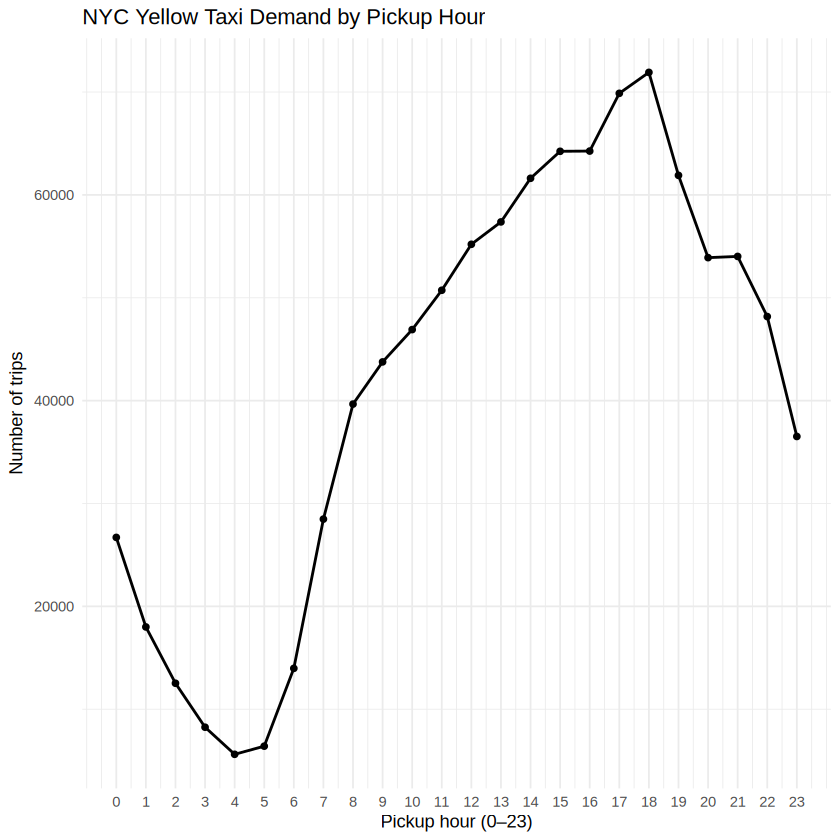

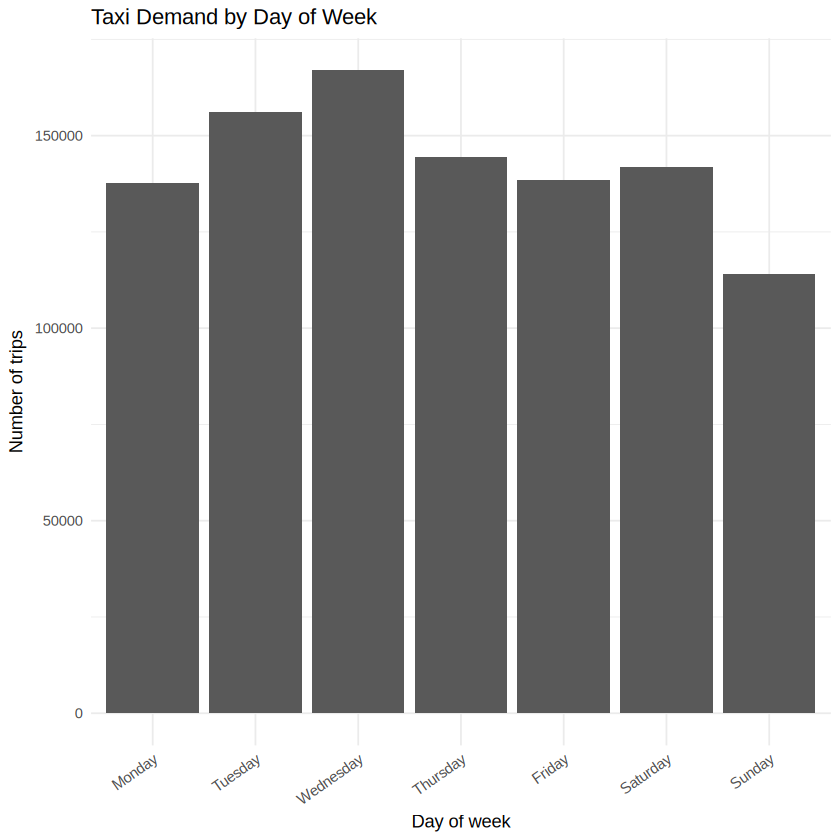

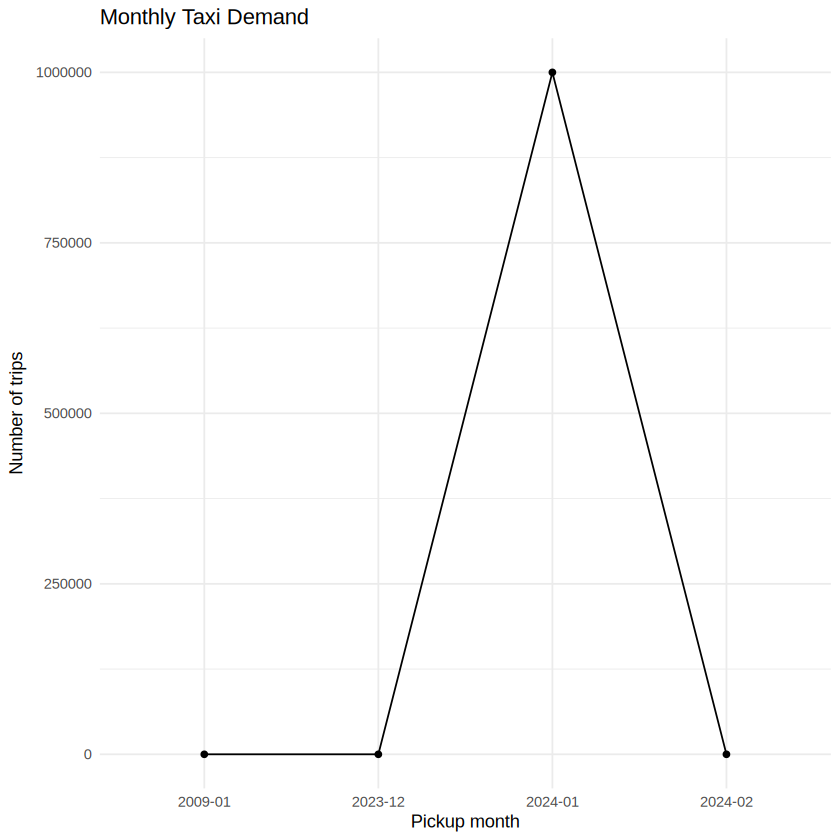

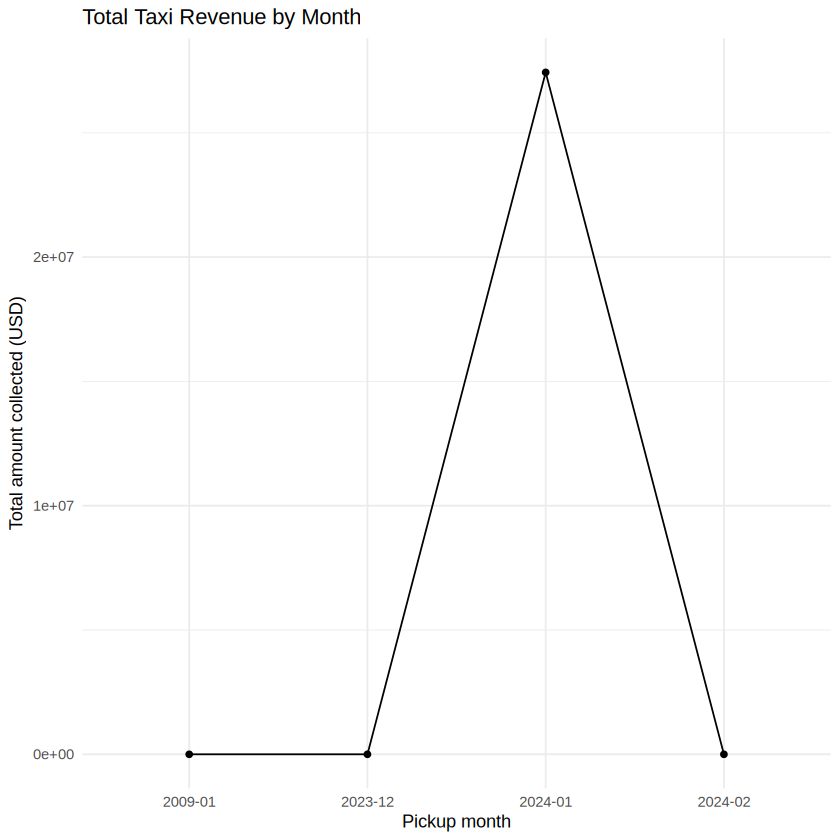

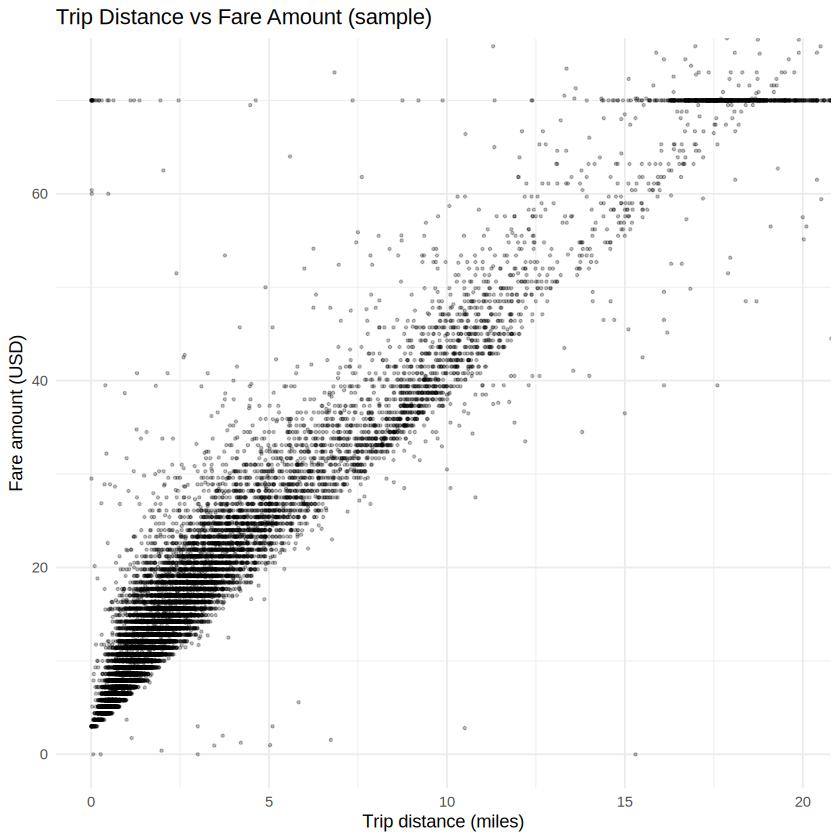

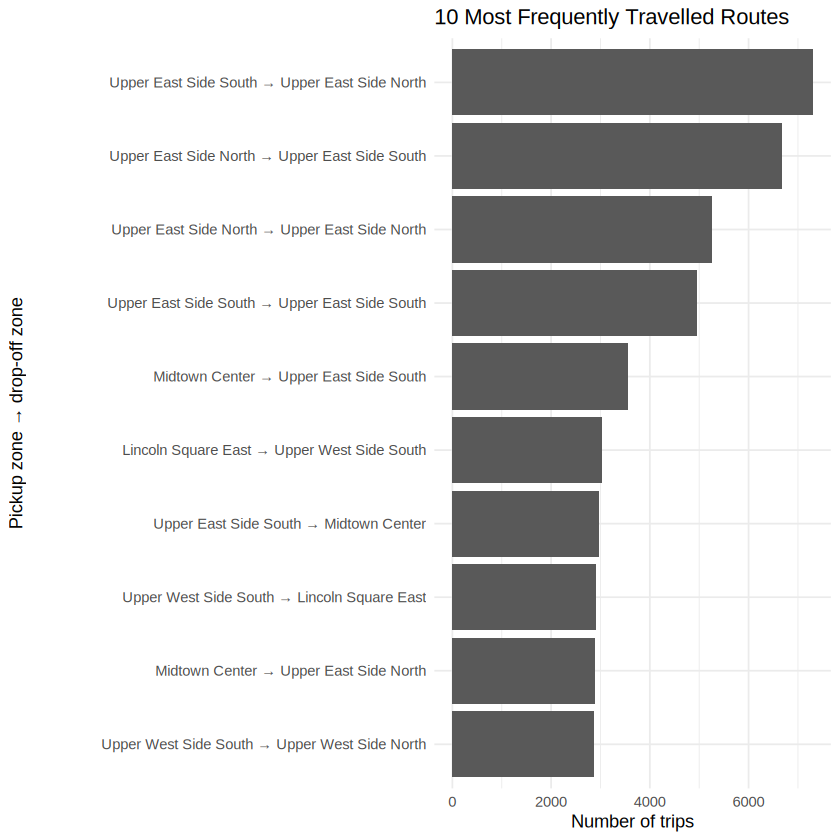

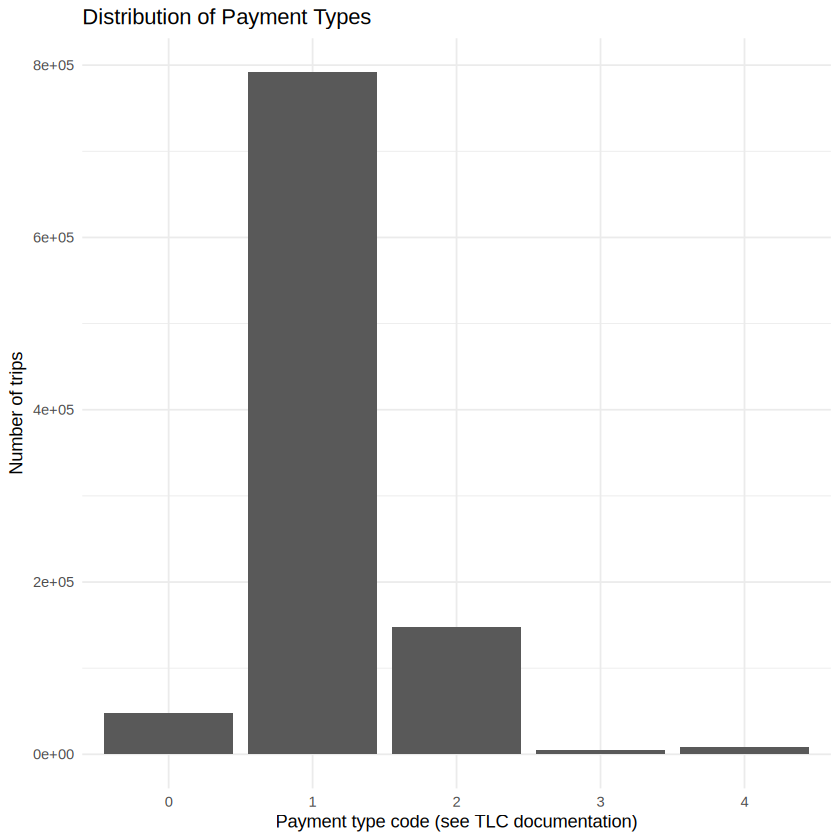

In [20]:
p_hour <- ggplot(trips_by_hour, aes(x = pickup_hour, y = trips)) +
  geom_line(linewidth = 0.8) + geom_point(size = 1.5) +
  scale_x_continuous(breaks = 0:23) +
  labs(title = "NYC Yellow Taxi Demand by Pickup Hour",
       x = "Pickup hour (0–23)", y = "Number of trips") +
  theme_minimal()
print(p_hour)

p_weekday <- ggplot(trips_by_weekday, aes(x = pickup_weekday, y = trips)) +
  geom_col() +
  labs(title = "Taxi Demand by Day of Week",
       x = "Day of week", y = "Number of trips") +
  theme_minimal() +
  theme(axis.text.x = element_text(angle = 35, hjust = 1))
print(p_weekday)

p_month <- ggplot(trips_by_month, aes(x = pickup_month, y = trips, group = 1)) +
  geom_line() + geom_point() +
  labs(title = "Monthly Taxi Demand",
       x = "Pickup month", y = "Number of trips") +
  theme_minimal()
print(p_month)

p_revenue <- ggplot(fare_revenue_by_month, aes(x = pickup_month, y = total_revenue, group = 1)) +
  geom_line() + geom_point() +
  labs(title = "Total Taxi Revenue by Month",
       x = "Pickup month", y = "Total amount collected (USD)") +
  theme_minimal()
print(p_revenue)

# Limit plotted records for readability and responsiveness.
set.seed(42)
plot_n <- min(20000L, nrow(distance_fare_sample))
plot_sample <- distance_fare_sample[sample(.N, plot_n)]
p_distance_fare <- ggplot(plot_sample, aes(x = trip_distance, y = fare_amount)) +
  geom_point(alpha = 0.25, size = 0.6) +
  coord_cartesian(xlim = c(0, quantile(plot_sample$trip_distance, 0.99, na.rm = TRUE)),
                  ylim = c(0, quantile(plot_sample$fare_amount, 0.99, na.rm = TRUE))) +
  labs(title = "Trip Distance vs Fare Amount (sample)",
       x = "Trip distance (miles)", y = "Fare amount (USD)") +
  theme_minimal()
print(p_distance_fare)

top_routes_plot <- copy(top_routes)
top_routes_plot[, route := paste(pickup_zone, "→", dropoff_zone)]
p_routes <- ggplot(top_routes_plot, aes(x = reorder(route, trips), y = trips)) +
  geom_col() + coord_flip() +
  labs(title = "10 Most Frequently Travelled Routes",
       x = "Pickup zone → drop-off zone", y = "Number of trips") +
  theme_minimal()
print(p_routes)

payment_summary <- taxi[, .(trips = .N), by = payment_type]
payment_summary[, payment_type := factor(payment_type)]
p_payment <- ggplot(payment_summary, aes(x = payment_type, y = trips)) +
  geom_col() +
  labs(title = "Distribution of Payment Types",
       x = "Payment type code (see TLC documentation)", y = "Number of trips") +
  theme_minimal()
print(p_payment)

## 11. Interpret results from this run

In [21]:
cat("=== DATASET SUMMARY ===\n")
cat("Rows analyzed:", format(nrow(taxi), big.mark = ","), "\n")
cat("Months selected:", paste(MONTHS, collapse = ", "), "\n")
cat("Unique pickup zones:", uniqueN(taxi$PULocationID), "\n")
cat("Unique drop-off zones:", uniqueN(taxi$DOLocationID), "\n")
cat("Mean trip distance (miles):", round(mean(taxi$trip_distance, na.rm = TRUE), 2), "\n")
cat("Median fare (USD):", round(median(taxi$fare_amount, na.rm = TRUE), 2), "\n")
cat("Total recorded amount (USD):", round(sum(taxi$total_amount, na.rm = TRUE), 2), "\n")

if (nrow(trips_by_hour) > 0) {
  peak_hour <- trips_by_hour[which.max(trips), pickup_hour]
  cat("Highest-demand pickup hour:", peak_hour, "\n")
}
if (nrow(trips_by_weekday[!is.na(pickup_weekday)]) > 0) {
  peak_day <- trips_by_weekday[which.max(trips), as.character(pickup_weekday)]
  cat("Highest-demand weekday:", peak_day, "\n")
}
if (nrow(top_routes) > 0) {
  cat("Most frequent route in analyzed data:",
      top_routes$pickup_zone[1], "to", top_routes$dropoff_zone[1],
      "with", top_routes$trips[1], "trips\n")
}
cat("\nUse the tables and plots above to describe demand, fare/revenue, route, distance, and payment patterns.\n")

=== DATASET SUMMARY ===
Rows analyzed: 1,000,000 
Months selected: 2024-01 
Unique pickup zones: 253 
Unique drop-off zones: 260 
Mean trip distance (miles): 3.53 
Median fare (USD): 12.8 
Total recorded amount (USD): 27429615 
Highest-demand pickup hour: 18 
Highest-demand weekday: Wednesday 
Most frequent route in analyzed data: Upper East Side South to Upper East Side North with 7302 trips

Use the tables and plots above to describe demand, fare/revenue, route, distance, and payment patterns.


## 12. Critical performance analysis

Use the **measured benchmark output from your own run** to complete this discussion. Do not assume parallel code is automatically faster.

- **`data.table`:** Usually well suited to large tabular data because grouping, filtering, and joins are implemented efficiently and by-reference updates can avoid unnecessary copies.
- **Vectorized/base R:** Often concise and fast for operations supported by optimized built-in functions; intermediate objects can increase memory use for some workflows.
- **`apply()`, `lapply()`, and `purrr::map()`:** Helpful for applying a repeated operation cleanly, especially across a list of partitions or different objects. They can be slower than a single vectorized or grouped operation when they repeatedly scan the full vector.
- **Sequential processing:** Has low setup and communication overhead and may win for modest tasks.
- **Parallel processing:** Can help when each partition has enough work, but worker startup, serialization, memory pressure, and combining results add overhead. The reported speedup is `sequential elapsed time / parallel elapsed time`.
- **Memory efficiency:** The notebook selects only needed Parquet columns, uses `data.table`, removes temporary objects where practical, and samples points for plotting.
- **Scalability:** Increase the number of months only if RAM and runtime allow. Compare performance on equivalent inputs and verify outputs before drawing conclusions.

In your report, cite the actual elapsed times and speedup printed in Sections 8–9, and explain why the results may differ on another machine.

## 13. Export results and save artifacts

In [22]:
RESULTS_DIR <- "lab8_results"
dir.create(RESULTS_DIR, showWarnings = FALSE)

fwrite(trips_by_hour, file.path(RESULTS_DIR, "trips_by_hour.csv"))
fwrite(trips_by_weekday, file.path(RESULTS_DIR, "trips_by_weekday.csv"))
fwrite(fare_revenue_by_month, file.path(RESULTS_DIR, "fare_revenue_by_month.csv"))
fwrite(top_routes, file.path(RESULTS_DIR, "top_routes_by_trip_count.csv"))
fwrite(top_revenue_routes, file.path(RESULTS_DIR, "top_routes_by_revenue.csv"))
fwrite(time_comparison, file.path(RESULTS_DIR, "benchmark_system_time.csv"))
fwrite(parallel_comparison, file.path(RESULTS_DIR, "sequential_vs_parallel.csv"))
write.csv(as.data.frame(benchmark_results), file.path(RESULTS_DIR, "microbenchmark_raw.csv"),
          row.names = FALSE)

cat("Result CSV files saved in:", RESULTS_DIR, "\n")
print(list.files(RESULTS_DIR))

Result CSV files saved in: lab8_results 
[1] "benchmark_system_time.csv"    "fare_revenue_by_month.csv"   
[3] "microbenchmark_raw.csv"       "sequential_vs_parallel.csv"  
[5] "top_routes_by_revenue.csv"    "top_routes_by_trip_count.csv"
[7] "trips_by_hour.csv"            "trips_by_weekday.csv"        


## 14. Conclusion

This laboratory workflow uses the NYC TLC Yellow Taxi dataset to demonstrate data preparation, zone lookup joins, temporal and route analytics, functional programming, vectorized and `data.table` implementations, sequential and parallel processing, benchmarking, and visualization.

The final conclusion should be based on the results printed during execution. In particular, report which hourly aggregation approach was fastest in your benchmark, the sequential and parallel elapsed times, calculated speedup, and any trade-offs in readability and memory usage. A benchmark on one Colab runtime is an experiment, not a universal guarantee of performance.